In [1]:

# WT vs Fmr1 LFP — Load animal-level data

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/Reanalysis/"
    "Our_Analysis/lfp/spontaneous"
)

OUT = BASE / "genotype_comparison" / "WT_vs_Fmr1"
OUT.mkdir(parents=True, exist_ok=True)

wt = pd.read_csv(
    BASE / "WT/processing/WT_LFP_all_animal_results.csv"
)

fmr = pd.read_csv(
    BASE / "Fmr1/processing/Fmr1_LFP_all_animal_results.csv"
)

data = pd.concat([wt, fmr], ignore_index=True)

assert not data.duplicated(
    ["subject", "genotype", "region", "subregion"]
).any(), "Duplicate animal-region observations found"

BANDS = [
    "Delta", "Theta", "Alpha-like",
    "Beta", "Low gamma", "High gamma"
]

# Count independent animals.
coverage = (
    data.groupby(
        ["region", "subregion", "genotype"]
    )["subject"]
    .nunique()
    .unstack(fill_value=0)
)

eligible = coverage.loc[
    (coverage["WT"] >= 5) &
    (coverage["Fmr1"] >= 5)
].index

data = (
    data.set_index(["region", "subregion"])
    .loc[eligible]
    .reset_index()
)

data.to_csv(OUT / "combined_animal_data.csv", index=False)
coverage.to_csv(OUT / "group_coverage.csv")

print("WT animals:", data.loc[
    data.genotype == "WT", "subject"
].nunique())

print("Fmr1 animals:", data.loc[
    data.genotype == "Fmr1", "subject"
].nunique())

print("Comparable anatomical groups:", len(eligible))
display(coverage)


Mounted at /content/drive
WT animals: 15
Fmr1 animals: 15
Comparable anatomical groups: 26


genotype          Fmr1  WT
region subregion          
APN    ALL          12   8
       APN          12   8
CA1    ALL          13  14
       CA1          13  14
CA3    ALL          12  11
       CA3          12  11
CP     ALL          12   9
       CP           12   9
DG     ALL          15  14
       DG-mo        15  14
       DG-po        13  12
       DG-sg        14  13
MOs    ALL          13  12
       MOs1         10   0
       MOs2/3       11  10
       MOs5         13  12
       MOs6a        13  10
       MOs6b         6   4
MRN    ALL          13  11
       MRN          13  11
SUB    ALL          11   9
       SUB          11   9
VISp   ALL          13  14
       VISp1         8   0
       VISp2/3      11  11
       VISp4        12  12
       VISp5        13  12
       VISp6a       13  14
       VISp6b       12  14

In [2]:

# WT vs Fmr1 — Statistical comparisons

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

rows = []

for (region, subregion), group in data.groupby(
    ["region", "subregion"]
):
    analysis_level = (
        "region" if subregion == "ALL"
        else "subregion"
    )

    for metric in ["absolute_uv2", "relative_pct"]:
        for band in BANDS:
            col = f"{band}_{metric}"

            x = group.loc[
                group.genotype == "WT", col
            ].dropna().to_numpy(dtype=float)

            y = group.loc[
                group.genotype == "Fmr1", col
            ].dropna().to_numpy(dtype=float)

            if min(len(x), len(y)) < 5:
                continue

            stat, p = mannwhitneyu(
                x, y, alternative="two-sided",
                method="auto"
            )

            # Positive delta means larger values in Fmr1.
            cliffs_delta = (
                np.sum(y[:, None] > x[None, :]) -
                np.sum(y[:, None] < x[None, :])
            ) / (len(x) * len(y))

            rows.append({
                "analysis_level": analysis_level,
                "region": region,
                "subregion": subregion,
                "band": band,
                "metric": metric,
                "n_WT": len(x),
                "n_Fmr1": len(y),
                "WT_median": np.median(x),
                "Fmr1_median": np.median(y),
                "MW_U": stat,
                "p_raw": p,
                "cliffs_delta_Fmr1_vs_WT": cliffs_delta
            })

results = pd.DataFrame(rows)

# Separate FDR families:
# 1. Anatomical level: region or subregion
# 2. Metric: absolute or relative power
results["p_FDR"] = np.nan

for (_, _), idx in results.groupby(
    ["analysis_level", "metric"]
).groups.items():
    results.loc[idx, "p_FDR"] = multipletests(
        results.loc[idx, "p_raw"],
        method="fdr_bh"
    )[1]

results["significant_FDR"] = results["p_FDR"] < 0.05

results = results.sort_values(
    ["analysis_level", "metric", "p_FDR"]
)

results.to_csv(
    OUT / "WT_vs_Fmr1_LFP_statistics.csv",
    index=False
)

print("Total comparisons:", len(results))
print("FDR significant:", results["significant_FDR"].sum())

display(results.head(30))


Total comparisons: 312
FDR significant: 0


,analysis_level,region,subregion,band,metric,n_WT,n_Fmr1,WT_median,Fmr1_median,MW_U,p_raw,cliffs_delta_Fmr1_vs_WT,p_FDR,significant_FDR
0,region,APN,ALL,Delta,absolute_uv2,8,12,5869.204889,3317.636743,60.0,0.383742,-0.250000,0.989987,False
1,region,APN,ALL,Theta,absolute_uv2,8,12,3371.931257,2739.056763,50.0,0.910106,-0.041667,0.989987,False
2,region,APN,ALL,Alpha-like,absolute_uv2,8,12,1002.274871,789.665203,49.0,0.969929,-0.020833,0.989987,False
3,region,APN,ALL,Beta,absolute_uv2,8,12,942.361973,796.104801,50.0,0.910106,-0.041667,0.989987,False
4,region,APN,ALL,Low gamma,absolute_uv2,8,12,355.774334,372.480432,43.0,0.734492,0.104167,0.989987,False
5,region,APN,ALL,High gamma,absolute_uv2,8,12,105.945877,120.255810,46.0,0.910106,0.041667,0.989987,False
24,region,CA1,ALL,Delta,absolute_uv2,14,13,3531.517138,3490.091006,83.0,0.715898,0.087912,0.989987,False
25,region,CA1,ALL,Theta,absolute_uv2,14,13,1949.983719,3264.658702,67.0,0.254134,0.263736,0.989987,False
26,region,CA1,ALL,Alpha-like,absolute_uv2,14,13,587.941585,965.633448,72.0,0.369327,0.208791,0.989987,False
27,region,CA1,ALL,Beta,absolute_uv2,14,13,861.311568,971.603426,74.0,0.423316,0.186813,0.989987,False


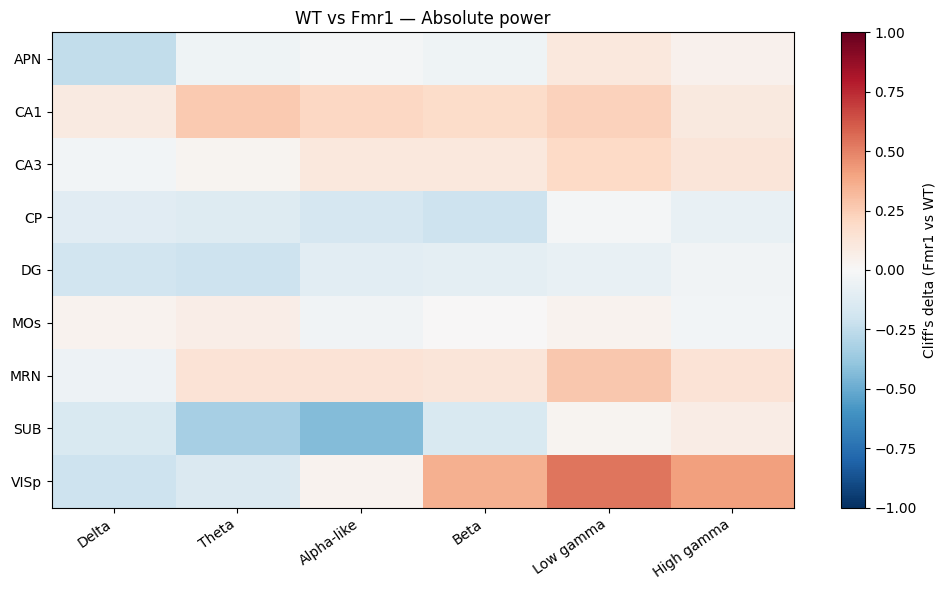

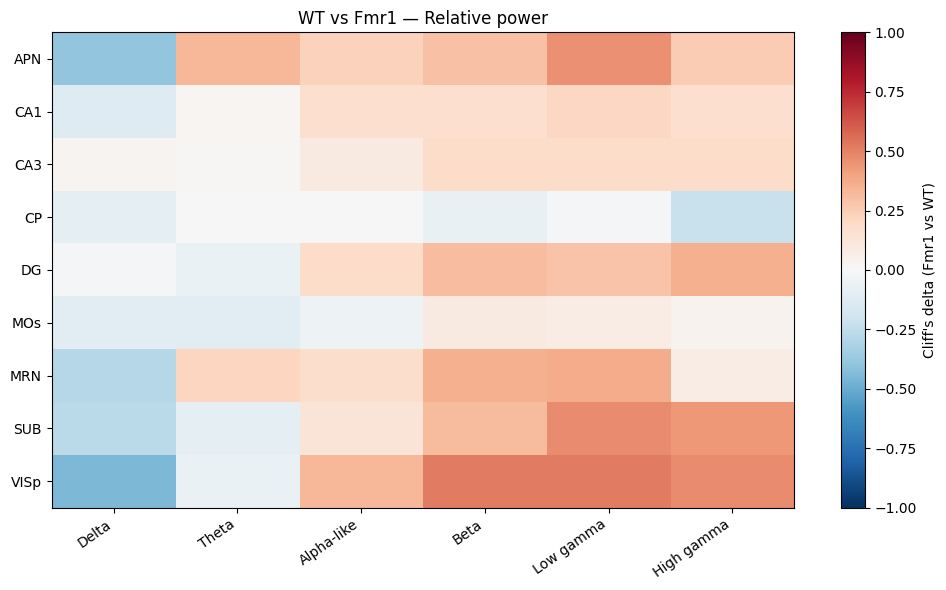

In [3]:

# WT vs Fmr1 — Effect-size heatmaps

import matplotlib.pyplot as plt

for metric, label in [
    ("absolute_uv2", "Absolute power"),
    ("relative_pct", "Relative power")
]:
    selected = results.loc[
        (results["metric"] == metric) &
        (results["analysis_level"] == "region")
    ]

    matrix = selected.pivot(
        index="region",
        columns="band",
        values="cliffs_delta_Fmr1_vs_WT"
    ).reindex(columns=BANDS)

    fig, ax = plt.subplots(figsize=(10, 6))

    im = ax.imshow(
        matrix.values,
        cmap="RdBu_r",
        vmin=-1, vmax=1,
        aspect="auto"
    )

    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns, rotation=35, ha="right")

    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index)

    # Mark FDR-significant cells.
    for i, region in enumerate(matrix.index):
        for j, band in enumerate(matrix.columns):
            hit = selected.loc[
                (selected.region == region) &
                (selected.band == band) &
                (selected.significant_FDR)
            ]
            if not hit.empty:
                ax.text(
                    j, i, "*",
                    ha="center", va="center",
                    fontsize=16, fontweight="bold"
                )

    plt.colorbar(
        im, ax=ax,
        label="Cliff's delta (Fmr1 vs WT)"
    )

    ax.set_title(f"WT vs Fmr1 — {label}")
    plt.tight_layout()

    filename = (
        "absolute" if metric == "absolute_uv2"
        else "relative"
    )

    plt.savefig(
        OUT / f"heatmap_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
